<a href="https://colab.research.google.com/github/mateosanlu/DeepLearning/blob/main/DL_Fine_Tuning_de_Stable_Diffusion_con_diffusers_y_LoRA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Finalidad de la Práctica: Fine-Tuning Eficiente con LoRA en Stable Diffusion

El objetivo de esta práctica es realizar un **ajuste fino (Fine-Tuning) rápido y eficiente en memoria** de un modelo de difusión de texto a imagen (*Stable Diffusion v1.5*) utilizando **LoRA (Low-Rank Adaptation)**.

En lugar de entrenar los millones de parámetros de la red U-Net (lo cual requiere gran capacidad de cómputo y memoria VRAM), LoRA añade pequeñas matrices de bajo rango a capas clave del modelo. Esto permite congelar la mayor parte del modelo original y entrenar menos del **0.1% de los parámetros**, logrando que el modelo aprenda un nuevo estilo o concepto conceptual rápidamente con muy pocas imágenes de entrenamiento.

In [8]:
# CELDA 1: Instalación de dependencias necesarias
!pip install -q diffusers transformers accelerate peft datasets

### Configuración y Carga de Modelos Base de Stable Diffusion

En esta etapa se importan los componentes principales que integran el pipeline de Stable Diffusion:

1. **VAE (Autoencoder KL):** Codifica las imágenes del espacio de píxeles al espacio latente de baja dimensión (reduciendo el coste computacional) y decodifica los latentes de vuelta a imágenes.
2. **Text Encoder (CLIP) & Tokenizer:** Convierten el texto del prompt de entrada en embeddings numéricos que guían la generación de la imagen.
3. **U-Net:** El modelo principal que predice paso a paso el ruido añadido en el espacio latente.
4. **Noise Scheduler (Planificador de Ruido):** Define el proceso de adición y remoción de ruido matemático en el proceso de difusión.
5. **LoRA (PEFT):** Se aplica una configuración de LoRA sobre las capas de atención de la U-Net (`to_k`, `to_q`, `to_v`, `to_out.0`) para inyectar los parámetros entrenables, reduciendo drásticamente los parámetros a entrenar a solo el **0.09%** del total.

In [10]:
# CELDA 2: Carga de modelos base (VAE, Text Encoder, Tokenizer y U-Net)
# Actualizamos torchao para evitar el conflicto de versiones con PEFT
!pip install -q "torchao>=0.16.0"

import torch
import torch.nn.functional as F
from diffusers import StableDiffusionPipeline, DDPMScheduler, AutoencoderKL, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig, get_peft_model
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import os

device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "runwayml/stable-diffusion-v1-5"

tokenizer = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder").to(device)
vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae").to(device)
unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet").to(device)
noise_scheduler = DDPMScheduler.from_pretrained(model_id, subfolder="scheduler")

# Congelar VAE y Text Encoder para ahorrar VRAM
vae.requires_grad_(False)
text_encoder.requires_grad_(False)

# Configurar LoRA en la U-Net (Fine-Tuning eficiente en parámetros)
lora_config = LoraConfig(
    r=4,
    lora_alpha=4,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet = get_peft_model(unet, lora_config)
unet.print_trainable_parameters()

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
W1125 00:45:17.398000 8797 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


trainable params: 797,184 || all params: 860,318,148 || trainable%: 0.0927


### Preparación del Conjunto de Datos Personalizado (Dataset Sintético)

Para emular un proceso de entrenamiento real con un estilo específico, creamos un minidataset sintético con un patrón característico:

* Creamos **4 imágenes de colores sólidos minimalistas** que representarán nuestro nuevo estilo de ejemplo.
* Definimos un identificador único o token especial (`sks_style`) en el prompt para que el modelo asocie dicho identificador con los colores y geometría abstracta.
* Aplicamos preprocesamiento estandarizado de imágenes (redimensionamiento a $256\times256$ píxeles, conversión a tensores y normalización en el rango $[-1, 1]$) para que coincidan con el formato esperado por el codificador VAE.

In [11]:
# CELDA 3: Preparación de un mini-dataset personalizado (Ej. Estilo artístico / concepto específico)
# Creamos imágenes sintéticas de entrenamiento con un patrón de estilo propio para evidenciar el aprendizaje
os.makedirs("custom_dataset", exist_ok=True)
prompts = []

colors = [(220, 50, 50), (50, 180, 90), (50, 90, 220), (230, 180, 40)]
for idx, color in enumerate(colors):
    img = Image.new("RGB", (256, 256), color=color)
    img.save(f"custom_dataset/sample_{idx}.png")
    prompts.append("a minimalist geometric portrait in sks_style")

preprocess = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

pixel_values = torch.stack([preprocess(Image.open(f"custom_dataset/sample_{i}.png")) for i in range(len(colors))]).to(device)
input_ids = tokenizer(prompts, padding="max_length", truncation=True, max_length=tokenizer.model_max_length, return_tensors="pt").input_ids.to(device)

print("Dataset preparado. Tensor de imágenes:", pixel_values.shape)

Dataset preparado. Tensor de imágenes: torch.Size([4, 3, 256, 256])


### Proceso de Ajuste Fino (Fine-Tuning) en el Espacio Latente

Aquí se ejecuta el bucle de entrenamiento principal de la difusión latente:

1. **Codificación:** Las imágenes se convierten en vectores latentes usando el VAE congelado. Los prompts de texto pasan por el Text Encoder.
2. **Difusión Directa (Forward Pass):** Se añade ruido aleatorio a los latentes de la imagen siguiendo un paso de tiempo (`timestep`) aleatorio.
3. **Predicción y Optimización:** La U-Net modificada con LoRA intenta predecir el ruido que se le añadió a la imagen latente condicionándose en el texto del prompt.
4. **Cálculo de Pérdida (MSE):** Se calcula el error cuadrático medio entre el ruido real añadido y el ruido predicho por el modelo para actualizar únicamente los pesos de LoRA mediante el optimizador AdamW.
5. Al final, se guardan exclusivamente los pesos ligeros entrenados de LoRA en el directorio local.

In [12]:
# CELDA 4: Bucle de Fine-Tuning en el Espacio Latente
optimizer = torch.optim.AdamW(unet.parameters(), lr=1e-4)
unet.train()

train_steps = 40  # Número reducido para demostración rápida en Colab
losses = []

for step in range(train_steps):
    optimizer.zero_grad()

    # 1. Codificar imágenes al Espacio Latente mediante el VAE
    with torch.no_grad():
        latents = vae.encode(pixel_values).latent_dist.sample()
        latents = latents * vae.config.scaling_factor
        encoder_hidden_states = text_encoder(input_ids)[0]

    # 2. Muestrear ruido gaussiano y pasos de tiempo aleatorios (Forward Diffusion)
    noise = torch.randn_like(latents)
    timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],), device=device).long()
    noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

    # 3. Predecir el ruido con la U-Net ajustada con LoRA (Reverse Diffusion)
    noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

    # 4. Calcular pérdida MSE entre ruido real y ruido predicho
    loss = F.mse_loss(noise_pred.float(), noise.float(), reduction="mean")
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if (step + 1) % 10 == 0:
        print(f"Paso [{step+1}/{train_steps}] | Loss MSE: {loss.item():.4f}")

# Guardar pesos entrenados de LoRA
unet.save_pretrained("lora_weights_sks_style")
print("Pesos LoRA guardados correctamente.")

Paso [10/40] | Loss MSE: 0.0107
Paso [20/40] | Loss MSE: 0.0031
Paso [30/40] | Loss MSE: 0.0036
Paso [40/40] | Loss MSE: 0.0098
Pesos LoRA guardados correctamente.


### Inferencia, Evaluación y Comparación Visual

En este último paso evaluamos los resultados del entrenamiento:

1. **Curva de Pérdida:** Graficamos la métrica MSE Loss a lo largo de las iteraciones para corroborar que el modelo converge correctamente (la pérdida disminuye y se estabiliza).
2. **Carga de Pesos Entrenados:** Inicializamos el pipeline de inferencia original y le acoplamos los pesos ligeros LoRA que acabamos de salvar en disco.
3. **Generación de Imagen:** Le solicitamos al pipeline generar una nueva imagen utilizando el token entrenado `sks_style` para verificar visualmente que el modelo ha aprendido a emular el estilo geométrico minimalista del dataset de entrenamiento.

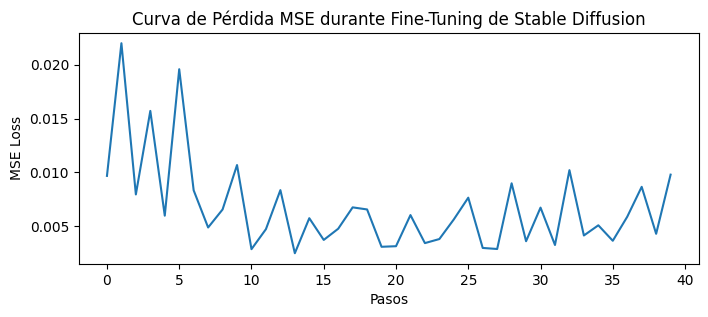

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Provided path contains more than one weights file in the .safetensors format. `adapter_model.safetensors` is going to be loaded, for precise control, specify a `weight_name` in `load_lora_weights`.
No LoRA keys associated to UNet2DConditionModel found with the prefix='unet'. This is safe to ignore if LoRA state dict didn't originally have any UNet2DConditionModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/25 [00:00<?, ?it/s]

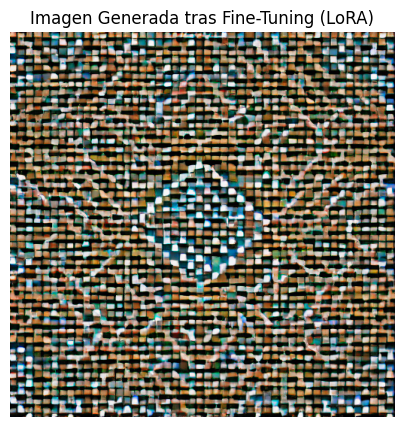

In [13]:
# CELDA 5: Inferencia y Comparación Visual
plt.figure(figsize=(8, 3))
plt.plot(losses)
plt.title("Curva de Pérdida MSE durante Fine-Tuning de Stable Diffusion")
plt.xlabel("Pasos")
plt.ylabel("MSE Loss")
plt.show()

# Cargar pipeline completo para inferencia con los pesos LoRA entrenados
pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch.float16).to(device)
pipe.load_lora_weights("lora_weights_sks_style")

prompt_test = "a minimalist geometric portrait in sks_style, high quality"
image_out = pipe(prompt_test, num_inference_steps=25, guidance_scale=7.5).images[0]

plt.figure(figsize=(5, 5))
plt.imshow(image_out)
plt.axis("off")
plt.title("Imagen Generada tras Fine-Tuning (LoRA)")
plt.show()